# Questions 4 and 5: Recurrent encoders, hyperparameter search and variance

## Question 4

We replace pooling by a recurrent encoder that reads the words in order. Base configuration: siamese bidirectional LSTM (hidden size 128, max pooling over time) on frozen Glove, pair combination [u; v; |u−v|; u⊙v], MLP with 1 hidden layer of 128, lr 1e-3, batch size 64, up to 15 epochs. We use early stopping on a 10% dev split of each training fold, so the validation fold is never used for decisions. 

After the one change at a time variants we combine the changes that helped (finetuning, hidden size 256, dropout 0.3, 25 epochs) and vary the learning rate and batch size on that combination.


In [16]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import baycomp

q4 = json.loads(Path("results/q4_glove.json").read_text())
q3 = json.loads(Path("results/q3_glove.json").read_text())
p1 = json.loads(Path("../project1/results/tuning_results.json").read_text())

MAJORITY_BASELINE = 0.558

runs = q4  
SEEDS = {"": 64, "_seed2": 1064, "_seed3": 2064} 
SEEDED = ["base", "finetune", "combined"]



**Results of all configurations compared to Q3 and Project 1**


In [17]:
def summarize(system, r):
    acc = np.array(r["accuracies"])
    row = {"System": system, "Mean accuracy": acc.mean() * 100, "Std over folds": acc.std(ddof=1) * 100}
    if "predictions" in r:
        row["Predicted paraphrase (%)"] = (np.array(r["predictions"]) == 1).mean() * 100
    if "histories" in r and "dev_accuracy" in r["histories"][0][0]:
        best = [int(np.argmax([h["dev_accuracy"] for h in fold])) + 1 for fold in r["histories"]]
        row["Best epoch (mean)"] = np.mean(best)
        row["Minutes"] = r.get("minutes", np.nan)
    return row

Q5_RUNS = ("_seed",)  
rows = [summarize(f"Q4 {name}", r) for name, r in q4.items() if not any(s in name for s in Q5_RUNS)]
best_q3 = max(q3, key=lambda n: q3[n]["mean_accuracy"])
rows.append(summarize(f"Q3 best ({best_q3})", q3[best_q3]))
rows.append(summarize("P1 indicator_deepmlp", p1["indicator_deepmlp"]))
rows.append({"System": "Majority baseline", "Mean accuracy": MAJORITY_BASELINE * 100})

results_df = pd.DataFrame(rows).sort_values("Mean accuracy", ascending=False).reset_index(drop=True)
display(results_df.round(2))


,System,Mean accuracy,Std over folds,Predicted paraphrase (%),Best epoch (mean),Minutes
0,Q4 combined_batch32,87.84,0.41,42.59,11.2,24.84
1,Q4 combined,87.83,0.41,43.05,11.6,12.61
2,Q4 combined_batch256,87.78,0.11,42.50,17.2,8.32
3,Q4 finetune_hidden256,87.67,0.64,43.26,8.0,9.77
4,Q4 finetune_dropout0.3,87.54,0.39,42.63,11.6,11.77
5,Q4 combined_lr3e-3,87.37,0.37,43.41,6.6,10.31
6,Q4 finetune,87.14,0.48,42.72,10.8,11.77
7,Q4 combined_lr3e-4,86.92,0.20,42.24,12.2,16.22
8,Q4 hidden256,85.85,0.51,42.23,12.6,12.18
9,Q4 random_init,85.62,0.61,42.89,10.2,10.81


**training loss, dev accuracy and validation accuracy per epoch**

Folds stop at different epochs because of early stopping.


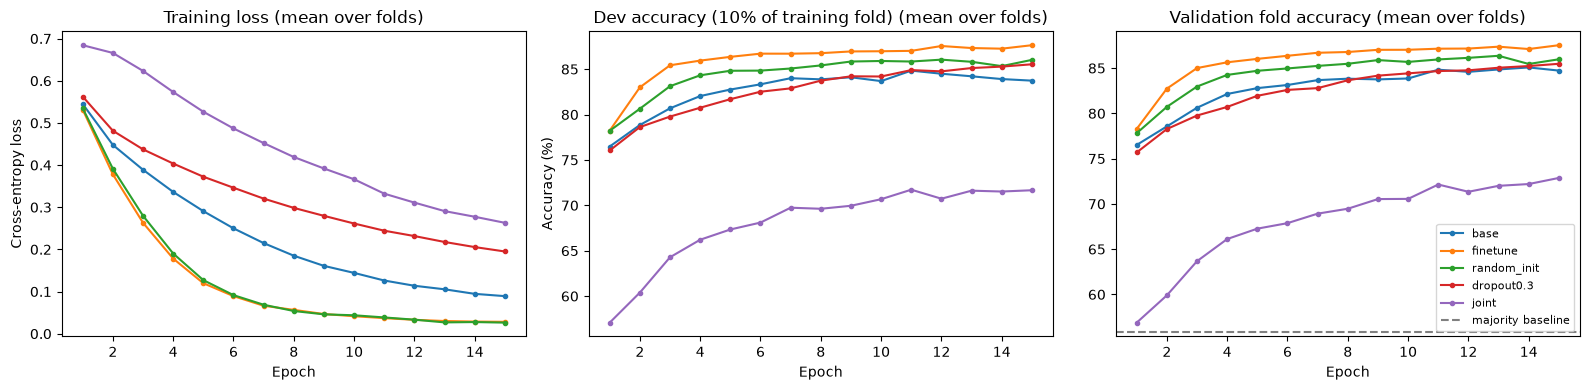

In [18]:
def mean_curve(r, key):
    n = max(len(fold) for fold in r["histories"])
    values = np.full((len(r["histories"]), n), np.nan)
    for i, fold in enumerate(r["histories"]):
        values[i, :len(fold)] = [h[key] for h in fold]
    return np.nanmean(values, axis=0)

shown = ["base", "finetune", "random_init", "dropout0.3", "joint"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in shown:
    for ax, key in zip(axes, ["train_loss", "dev_accuracy", "val_accuracy"]):
        curve = mean_curve(q4[name], key)
        if key != "train_loss":
            curve = curve * 100
        ax.plot(np.arange(1, len(curve) + 1), curve, marker="o", markersize=3, label=name)

for ax, title in zip(axes, ["Training loss", "Dev accuracy (10% of training fold)", "Validation fold accuracy"]):
    ax.set_title(title + " (mean over folds)")
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_ylabel("Accuracy (%)")
axes[2].axhline(MAJORITY_BASELINE * 100, color="grey", linestyle="--", label="majority baseline")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()


**Effect of training data size** base configuration trained on 10%, 25%, 50% and 100% of each training fold


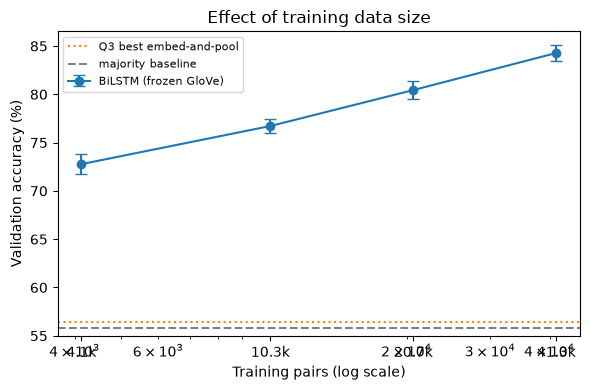

In [19]:
fractions = {"data10": 0.1, "data25": 0.25, "data50": 0.5, "base": 1.0}
n_train = len(q4["base"]["predictions"]) * 0.8 * 0.9  # 4/5 of the data per fold, minus the 10% dev split
sizes = [f * n_train for f in fractions.values()]
means = [q4[n]["mean_accuracy"] * 100 for n in fractions]
stds = [np.std(q4[n]["accuracies"], ddof=1) * 100 for n in fractions]

plt.figure(figsize=(6, 4))
plt.errorbar(sizes, means, yerr=stds, marker="o", capsize=4, label="BiLSTM (frozen GloVe)")
plt.axhline(q3[best_q3]["mean_accuracy"] * 100, color="tab:orange", linestyle=":", label="Q3 best embed-and-pool")
plt.axhline(MAJORITY_BASELINE * 100, color="grey", linestyle="--", label="majority baseline")
plt.xscale("log")
plt.xticks(sizes, [f"{s / 1000:.1f}k" for s in sizes])
plt.xlabel("Training pairs (log scale)")
plt.ylabel("Validation accuracy (%)")
plt.title("Effect of training data size")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Bayesian comparison with ROPE (±1%)**


In [20]:
def rope_compare(name_a, acc_a, name_b, acc_b, rope=0.01):
    p_a, p_equal, p_b = baycomp.two_on_single(np.array(acc_a), np.array(acc_b), rope=rope, runs=1)
    return {"A": name_a, "B": name_b, "P(A better)": p_a, "P(equal)": p_equal, "P(B better)": p_b}

def q4_compare(a, b):
    return rope_compare(f"Q4 {a}", q4[a]["accuracies"], f"Q4 {b}", q4[b]["accuracies"])

comparisons = [
    rope_compare("Q4 base", q4["base"]["accuracies"], f"Q3 {best_q3}", q3[best_q3]["accuracies"]),
    rope_compare("Q4 base", q4["base"]["accuracies"], "P1 indicator_deepmlp", p1["indicator_deepmlp"]["accuracies"]),
    q4_compare("base", "joint"),
    q4_compare("base", "gru"),
    q4_compare("base", "unidirectional"),
    q4_compare("base", "rnn_pool_last"),
    q4_compare("hidden256", "base"),
    q4_compare("base", "hidden64"),
    q4_compare("dropout0.3", "base"),
    q4_compare("finetune", "base"),
    q4_compare("finetune", "random_init"),
    q4_compare("random_init", "base"),
]
display(pd.DataFrame(comparisons).round(3))


,A,B,P(A better),P(equal),P(B better)
0,Q4 base,Q3 pool_max,1.000,0.000,0.000
1,Q4 base,P1 indicator_deepmlp,1.000,0.000,0.000
2,Q4 base,Q4 joint,0.999,0.000,0.000
3,Q4 base,Q4 gru,0.022,0.970,0.009
4,Q4 base,Q4 unidirectional,0.391,0.587,0.023
5,Q4 base,Q4 rnn_pool_last,0.976,0.023,0.001
6,Q4 hidden256,Q4 base,0.853,0.144,0.003
7,Q4 base,Q4 hidden64,0.433,0.564,0.003
8,Q4 dropout0.3,Q4 base,0.816,0.184,0.000
9,Q4 finetune,Q4 base,0.997,0.003,0.000


**Combining the changes that helped** (finetuning, hidden size 256, dropout 0.3, with 25 epochs because some models were still improving at 15). 


In [21]:
combos = ["base", "hidden256", "dropout0.3", "finetune", "finetune_hidden256", "finetune_dropout0.3", "combined"]
base_acc = runs["base"]["mean_accuracy"] * 100
gain = {n: runs[n]["mean_accuracy"] * 100 - base_acc for n in combos}
additive = {
    "finetune_hidden256": gain["finetune"] + gain["hidden256"],
    "finetune_dropout0.3": gain["finetune"] + gain["dropout0.3"],
    "combined": gain["finetune"] + gain["hidden256"] + gain["dropout0.3"],
}
combo_df = pd.DataFrame({
    "Configuration": combos,
    "Mean accuracy": [runs[n]["mean_accuracy"] * 100 for n in combos],
    "Gain over base": [gain[n] for n in combos],
    "Gain if effects added up": [additive.get(n, np.nan) for n in combos],
    "Best epoch (mean)": [np.mean([np.argmax([h["dev_accuracy"] for h in fold]) + 1 for fold in runs[n]["histories"]])
                          for n in combos],
})
display(combo_df.round(2))


,Configuration,Mean accuracy,Gain over base,Gain if effects added up,Best epoch (mean)
0,base,84.28,0.00,NaN,9.4
1,hidden256,85.85,1.57,NaN,12.6
2,dropout0.3,85.53,1.25,NaN,14.8
3,finetune,87.14,2.86,NaN,10.8
4,finetune_hidden256,87.67,3.38,4.43,8.0
5,finetune_dropout0.3,87.54,3.26,4.11,11.6
6,combined,87.83,3.55,5.68,11.6


Learning rate and batch size  tested on the combined configuration and compared to combined with seed 64


In [22]:
settings = {
    "combined": "lr 1e-3, batch 64 (combined)",
    "combined_lr3e-4": "lr 3e-4",
    "combined_lr3e-3": "lr 3e-3",
    "combined_batch32": "batch 32",
    "combined_batch256": "batch 256",
}
seed_means = [runs["combined" + s]["mean_accuracy"] * 100 for s in SEEDS]
print(f"combined over 3 seeds: {min(seed_means):.2f}–{max(seed_means):.2f}%")

rows = []
for name, label in settings.items():
    r = runs[name]
    best = [int(np.argmax([h["dev_accuracy"] for h in fold])) + 1 for fold in r["histories"]]
    row = {"Setting": label, "Mean accuracy": r["mean_accuracy"] * 100,
           "Best epoch (mean)": np.mean(best), "Minutes": r["minutes"]}
    if name != "combined":
        p = rope_compare(name, r["accuracies"], "combined", runs["combined"]["accuracies"])
        row.update({"P(better than combined)": p["P(A better)"], "P(equal)": p["P(equal)"],
                    "P(worse than combined)": p["P(B better)"]})
    rows.append(row)
display(pd.DataFrame(rows).round(3))


combined over 3 seeds: 87.82–88.06%


,Setting,Mean accuracy,Best epoch (mean),Minutes,P(better than combined),P(equal),P(worse than combined)
0,"lr 1e-3, batch 64 (combined)",87.828,11.6,12.613,NaN,NaN,NaN
1,lr 3e-4,86.924,12.2,16.219,0.003,0.593,0.403
2,lr 3e-3,87.366,6.6,10.312,0.018,0.826,0.157
3,batch 32,87.838,11.2,24.843,0.038,0.926,0.036
4,batch 256,87.781,17.2,8.321,0.013,0.970,0.017


**Conclusion Q4**

Design choices:
- Reading the words in order makes the difference. The base BiLSTM gets 84.3% against 56.4% for the best embed-and-pool model and 58.7% for Project 1.
- Siamese encoding works much better than one joint encoder over "s1 [SEP] s2" with 84.3% vs 71.2%, and joint also varies a lot between folds. The siamese model compares the two sentence vectors directly with |u−v| and u⊙v. The joint model has to carry sentence 1 past [SEP] and max pooling mixes both sentences.
- GRU vs LSTM makes no difference with 97% probability equal. Bidirectional vs unidirectional and hidden size 128 vs 64 are probably equal too with 59% and 56%. Max pooling over time beats the last hidden state with 84.3% vs 82.2% and 97.6% probability, because the last state has to summarise the whole sentence.
- Hidden size 256 gives 85.9% and dropout 0.3 gives 85.5%, so both help a bit. They were still improving at the 15 epoch limit.





Data size:
- 10% to 25% to 50% to 100% of the training data gives 72.8% to 76.7% to 80.4% to 84.3% so about +4 points per doubling. Even with 10% of the data the BiLSTM beats all models from Q3 and Project 1.

Embedding parameters:
- Finetuning Glove is the best single change with 87.1%, better than frozen with probability 0.997. Trained random embeddings get 85.6% which is already better than frozen Glove at 84.3%, so being able to adapt the embeddings matters more than pretraining here. Pretraining still helps since finetuned Glove beats random embeddings with probability 0.95.


Overfitting:
- Finetuning brings the training loss down to 0.03  while validation accuracy stays at about 87%. Early stopping on the dev split keeps the best epoch so overfitting does not hurt the final score. The full data models predict 41–43% paraphrases which is close to the true 44.2% so they no longer fall back to the majority class.

How far does this approach go:
- Combining finetuning, hidden size 256 and dropout with 25 epochs gives 87.8%, up from 87.1% for finetuning alone and more than 30 points above embed and pool (56.4%). The gains do not add up though, separately they would give +5.7 over base, together they give +3.6. With 25 epochs all folds stopped early so the epoch limit no longer held the model back.
- Learning rate 1e-3 is the best of 3e-4, 1e-3 and 3e-3, but the differences are pretty modest for example 3e-4 is 0.9 points lower with a 40% probability that it's worse and 3e-3 is 0.5 lower with a 83% probability equal. Batch size makes no difference (32, 64 and 256 are 93–97% equal), but batch 256 trains 3× faster than batch 32.



## Question 5: Hyperparameter search and experimental variance


How we structured the search:
- We start from one base configuration and change one thing at a time, so each difference can be traced back to one choice. Then we combine the changes that helped and tune the learning rate and batch size on that combination.
- All runs use the same 5 folds as Project 1, so results are paired per fold. The number of epochs is chosen with early stopping on a 10% dev split of the training fold and never on the validation fold.
- We compare configurations with a Bayesian correlated t-test with a ROPE of ±1%, which takes the variance between folds into account.
- In Project 1 we used a small grid search because the models were fast. Here each LSTM run takes about 10 minutes and there are many more settings, so a full grid would take hundreds of runs.
- Because one change at a time needs few runs, we can spend the saved compute on multiple seeds for the decisions that matter.


Weaknesses of this structure:
- It misses interactions, two changes that each help may not help together. The combinations show this happens.
- Every variant was run with one seed so we don't know how much of a difference comes from initialisation and data order alone. We test this with three seeds for base, finetune and the combined configuration. A seed changes the initialisation, the order of the training data and the dev split but not the folds.
- The results depend on the base we picked. Changes that help the frozen model may not help the finetuned one.


**Variance between seeds**


In [23]:
rows = []
for name in SEEDED:
    means = [runs[name + s]["mean_accuracy"] * 100 for s in SEEDS]
    fold_stds = [np.std(runs[name + s]["accuracies"], ddof=1) * 100 for s in SEEDS]
    rows.append({
        "Configuration": name,
        **{f"Seed {seed}": m for seed, m in zip(SEEDS.values(), means)},
        "Mean over seeds": np.mean(means),
        "Std between seeds": np.std(means, ddof=1),
        "Range between seeds": max(means) - min(means),
        "Std between folds (mean)": np.mean(fold_stds),
    })
display(pd.DataFrame(rows).round(2))


,Configuration,Seed 64,Seed 1064,Seed 2064,Mean over seeds,Std between seeds,Range between seeds,Std between folds (mean)
0,base,84.28,84.68,84.20,84.39,0.26,0.48,0.68
1,finetune,87.14,87.18,86.64,86.99,0.30,0.54,0.40
2,combined,87.83,87.82,88.06,87.90,0.14,0.24,0.39


**Which Q4 differences are larger than the seed variance?** The grey band shows how much the base model moves when only the seed changes.


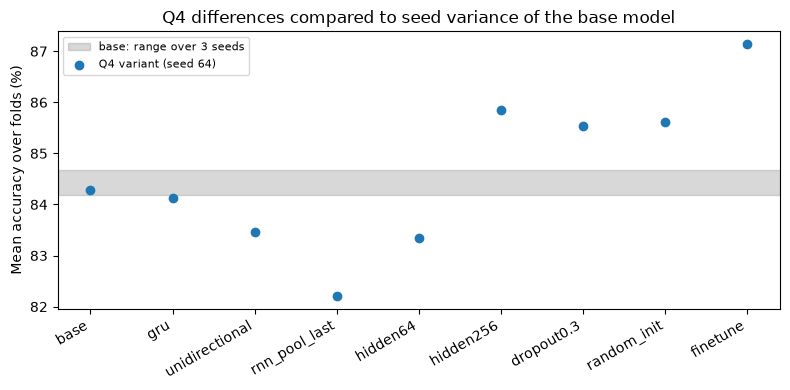

In [24]:
q4_variants = ["base", "gru", "unidirectional", "rnn_pool_last", "hidden64", "hidden256",
               "dropout0.3", "random_init", "finetune"]
base_seeds = [runs["base" + s]["mean_accuracy"] * 100 for s in SEEDS]
means = [runs[n]["mean_accuracy"] * 100 for n in q4_variants]

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhspan(min(base_seeds), max(base_seeds), color="grey", alpha=0.3, label="base: range over 3 seeds")
ax.scatter(range(len(q4_variants)), means, color="tab:blue", zorder=3, label="Q4 variant (seed 64)")
ax.set_xticks(range(len(q4_variants)))
ax.set_xticklabels(q4_variants, rotation=30, ha="right")
ax.set_ylabel("Mean accuracy over folds (%)")
ax.set_title("Q4 differences compared to seed variance of the base model")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Bayesian comparison with ROPE (±1%), with all three seeds and with one seed at a time**


In [25]:
def all_seeds(name):
    return np.concatenate([runs[name + s]["accuracies"] for s in SEEDS])

def rope_compare(name_a, acc_a, name_b, acc_b, n_runs=1, rope=0.01):
    p_a, p_equal, p_b = baycomp.two_on_single(np.array(acc_a), np.array(acc_b), rope=rope, runs=n_runs)
    return {"A": name_a, "B": name_b, "Seeds": n_runs, "P(A better)": p_a, "P(equal)": p_equal, "P(B better)": p_b}

comparisons = [
    rope_compare("combined", all_seeds("combined"), "finetune", all_seeds("finetune"), 3),
    rope_compare("finetune", all_seeds("finetune"), "base", all_seeds("base"), 3),
    rope_compare("combined", all_seeds("combined"), "base", all_seeds("base"), 3),
]
for s in SEEDS:
    comparisons.append(rope_compare(f"combined{s}", runs["combined" + s]["accuracies"],
                                    f"finetune{s}", runs["finetune" + s]["accuracies"], 1))
display(pd.DataFrame(comparisons).round(3))


,A,B,Seeds,P(A better),P(equal),P(B better)
0,combined,finetune,3,0.407,0.593,0.000
1,finetune,base,3,1.000,0.000,0.000
2,combined,base,3,1.000,0.000,0.000
3,combined,finetune,1,0.200,0.796,0.004
4,combined_seed2,finetune_seed2,1,0.171,0.824,0.004
5,combined_seed3,finetune_seed3,1,0.830,0.168,0.002


**Conclusion Q5**

Experimental variance:
- Changing only the seed moves the mean accuracy by up to 0.5 points, with a standard deviation between seeds of 0.14 to 0.30. That is smaller than the variance between folds of 0.4 to 0.7 but not negligible.
- So some Q4 conclusions are not reliable. GRU vs LSTM differs by only 0.15 which is within seed noise, and unidirectional and hidden size 64 are about 0.9 lower which is only just outside it. The large effects hold, finetuning beats frozen embeddings with probability 1.000 over all three seeds.

Hyperparameter search:
- One change at a time misses interactions. Hidden size 256 and dropout help the frozen model but add little once the embeddings are trainable. Part of this may be a ceiling effect since close to the best possible accuracy each extra point is harder to gain.
- The combined model is probably the best with 87.9% averaged over seeds and also the most stable with a standard deviation of 0.14. Compared to finetuning alone the difference is within the ROPE with 41% probability better and 59% equal.
- With a single seed we could have drawn the wrong conclusion. For two seeds combined vs finetune is about 80% equal and for the third seed combined is 83% better, so decisions about small differences need several seeds.
- Our best configuration was chosen on the same cross-validation results we report so its score is slightly optimistic. The differences between the top configurations are small so this bias is limited.

Why this structure and what we would change:
- One change at a time followed by targeted checks was much cheaper than a full grid search and still caught the interactions. We may have missed a slightly better combination but the gains were already shrinking and the learning rate and batch size barely mattered, so we don't expect a big difference. A larger gain would more likely come from a different architecture than from more tuning.
- The one thing we would change is running several seeds from the start for the main comparisons, because with a single seed some small differences like GRU vs LSTM looked meaningful when they were noise.
